In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib
import os

In [2]:
rfm_scaled = pd.read_csv(
    "../data/processed/customer_rfm_scaled.csv",
    index_col="CustomerID"
)

print(rfm_scaled.shape)
rfm_scaled.head()

(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


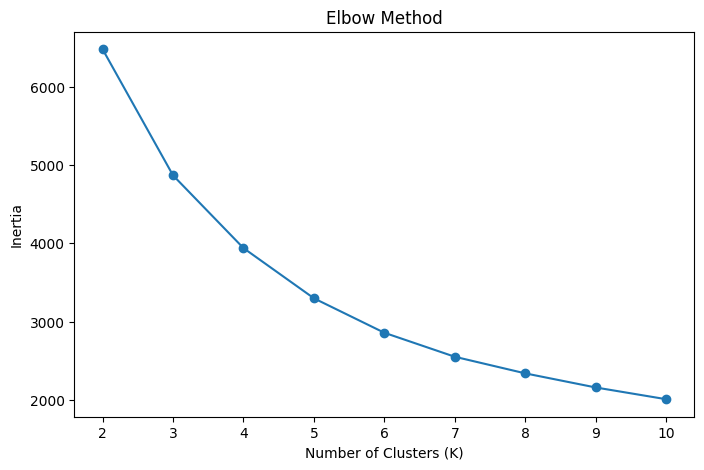

In [3]:
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [4]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4328
K = 3, Silhouette Score = 0.3365
K = 4, Silhouette Score = 0.3375
K = 5, Silhouette Score = 0.3162
K = 6, Silhouette Score = 0.3124
K = 7, Silhouette Score = 0.3092
K = 8, Silhouette Score = 0.3033
K = 9, Silhouette Score = 0.2811
K = 10, Silhouette Score = 0.2767


In [5]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(rfm_scaled)

rfm_scaled["Cluster"] = clusters

rfm_scaled.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,1.461993,-0.955214,3.707716,3
12347,-2.038734,1.074425,1.414903,0
12348,0.373104,0.386304,0.720024,3
12349,-0.623086,-0.955214,0.702287,2
12350,1.424558,-0.955214,-0.614514,1


In [6]:
print(rfm_scaled["Cluster"].value_counts().sort_index())

Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


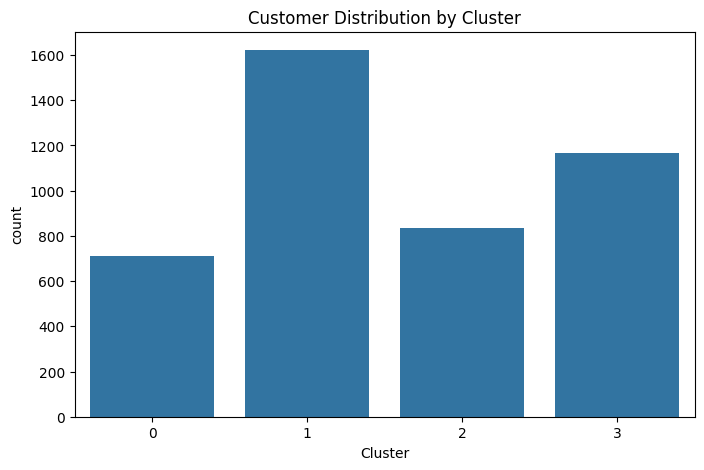

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm_scaled,
    x="Cluster"
)

plt.title("Customer Distribution by Cluster")
plt.show()

In [8]:
rfm = pd.read_csv(
    "../data/processed/customer_rfm.csv",
    index_col="CustomerID"
)

rfm["Cluster"] = clusters

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1


In [9]:
cluster_analysis = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

display(cluster_analysis)

,Recency,Frequency,Monetary
Cluster,,,
0,12.17,13.75,8088.02
1,181.51,1.32,341.00
2,17.70,2.19,557.32
3,71.64,4.08,1801.78


In [10]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

joblib.dump(
    kmeans,
    "../models/kmeans_model.pkl"
)

rfm.to_csv(
    "../data/processed/customer_segments.csv"
)

print("K-Means model and customer segments saved!")

K-Means model and customer segments saved!
